# HealthPulse AI 360 — J3 : Extraction, structuration et fiabilisation des données sur le diabète

## Objectif
Récupérer les premières données officielles de l'Assurance Maladie à l'aide de Python sur le diabète .

## Source
- Organisme : Assurance Maladie (CNAM)
- Portail : Data ameli
- Jeu de données : Effectifs par pathologie (diabète)
- Période disponible : 2015–2024
- Échelle : département et région

## Méthodologie
1. Tester l'API.
2. Importer les données liées au diabète sur l'année 2024.
3. Explorer les colonnes.
4. Contrôler la qualité.
5. Sauvegarder les données brutes.

## 1. Reprendre l'extraction du J2

In [1]:
import os

os.environ["OMP_NUM_THREADS"] = "4"
os.environ["NUMEXPR_NUM_THREADS"] = "4"

In [2]:
import pandas as pd
import requests
from pathlib import Path

RACINE = Path(r"D:\HealthPulse_AI_360")

RAW = RACINE / "data" / "raw" / "diabete"
INTERIM = RACINE / "data" / "interim" / "diabete"

RAW.mkdir(parents=True, exist_ok=True)
INTERIM.mkdir(parents=True, exist_ok=True)

In [3]:
BASE_URL = (
    "https://data.ameli.fr/api/explore/v2.1/"
    "catalog/datasets/effectifs"
)

## 2. Exporter le schéma officiel

In [4]:
reponse = requests.get(BASE_URL, timeout=30)

print("HTTP :", reponse.status_code)

reponse.raise_for_status()

metadata = reponse.json()

print(metadata.keys())

HTTP : 200
dict_keys(['visibility', 'fields', 'dataset_id', 'dataset_uid', 'has_records', 'features', 'attachments', 'alternative_exports', 'data_visible', 'metas'])


In [5]:
#Récupérer les métadonnées

champs = pd.DataFrame(metadata.get("fields", []))

print(champs.columns.tolist())

display(champs.head(10))

['name', 'description', 'annotations', 'label', 'type']


,name,description,annotations,label,type
0,annee,année,"{'facet': True, 'facetsort': '-count', 'timese...",annee,date
1,patho_niv1,groupe de pathologies (ou traitements chroniqu...,{'facet': True},patho_niv1,text
2,patho_niv2,sous-groupe de pathologies (ou traitements chr...,{'facet': True},patho_niv2,text
3,patho_niv3,sous-groupe détaillé de pathologies (ou traite...,{'facet': True},patho_niv3,text
4,top,libellé technique de la pathologie (ou traitem...,{'id': True},top,text
5,cla_age_5,classe d’âge (5 ans)\n,{'id': True},cla_age_5,text
6,sexe,sexe,"{'facetsort': '-count', 'id': True}",sexe,text
7,region,région,"{'facet': True, 'id': True, 'facetsort': '-cou...",region,text
8,dept,département,"{'facet': True, 'facetsort': '-count', 'id': T...",dept,text
9,ntop,effectif de patients pris en charge pour la pa...,{'facetsort': '-count'},Ntop,int


## 3. Construire une extraction ciblée

- annee = 2024
- pathologie = 'Diabète'
- territoire = 'Département'

In [6]:
import requests
from pathlib import Path

# Chemin du projet
dossier = Path(r"D:\HealthPulse_AI_360\data\raw\diabete")
dossier.mkdir(parents=True, exist_ok=True)

# Endpoint d'export
url_export = BASE_URL + "/exports/csv"

# Filtre diabète en 2024
condition = 'year(annee) = 2024 AND patho_niv1 = "Diabète"'

params = {
    "where": condition,
    "delimiter": ";"
}

fichier = dossier / "diabete_2024_complet.csv"

# Télécharger sans charger tout le fichier en RAM
with requests.get(
    url_export,
    params=params,
    stream=True,
    timeout=(15, 180)
) as reponse:

    reponse.raise_for_status()

    with open(fichier, "wb") as f:
        for bloc in reponse.iter_content(chunk_size=1024 * 1024):
            if bloc:
                f.write(bloc)

print("Fichier exporté :", fichier)
print("Taille (Mo) :", round(fichier.stat().st_size / 1024**2, 2))

Fichier exporté : D:\HealthPulse_AI_360\data\raw\diabete\diabete_2024_complet.csv
Taille (Mo) : 0.79


In [7]:
df_diabete = pd.read_csv(
    fichier,
    sep=";",
    encoding="utf-8-sig",
    low_memory=False
)

print("Dimensions :", df_diabete.shape)

display(df_diabete.head())

Dimensions : (7560, 16)


,annee,patho_niv1,patho_niv2,patho_niv3,top,cla_age_5,sexe,region,dept,ntop,npop,prev,niveau_prioritaire,libelle_classe_age,libelle_sexe,tri
0,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,90-94,2,2,999,860.0,2820,30.429,"1,2,3",de 90 à 94 ans,femmes,2.0
1,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,90-94,2,4,999,970.0,2910,33.150,"1,2,3",de 90 à 94 ans,femmes,2.0
2,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,90-94,2,6,999,10.0,80,14.474,"1,2,3",de 90 à 94 ans,femmes,2.0
3,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,90-94,2,11,77,1320.0,7700,17.112,"1,2,3",de 90 à 94 ans,femmes,2.0
4,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,90-94,2,11,78,1220.0,9410,12.986,"1,2,3",de 90 à 94 ans,femmes,2.0


In [8]:
print(df_diabete.columns.tolist())

print(df_diabete["patho_niv1"].unique())

print(df_diabete["annee"].unique())

['annee', 'patho_niv1', 'patho_niv2', 'patho_niv3', 'top', 'cla_age_5', 'sexe', 'region', 'dept', 'ntop', 'npop', 'prev', 'niveau_prioritaire', 'libelle_classe_age', 'libelle_sexe', 'tri']
['Diabète']
[2024]


## 4. Contrôler et fiabiliser les données

In [9]:
#Idnetifier les dimensions

colonnes = [
    "patho_niv1",
    "patho_niv2",
    "patho_niv3",
    "niveau_prioritaire",
    "annee",
    "dept",
    "region",
    "sexe",
    "cla_age_5"
]

for col in colonnes:
    if col in df_diabete.columns:
        print(f"\n--- {col} ---")
        print(df_diabete[col].value_counts(dropna=False).head(20))


--- patho_niv1 ---
patho_niv1
Diabète    7560
Name: count, dtype: int64

--- patho_niv2 ---
patho_niv2
Diabète    7560
Name: count, dtype: int64

--- patho_niv3 ---
patho_niv3
Diabète    7560
Name: count, dtype: int64

--- niveau_prioritaire ---
niveau_prioritaire
1,2,3    7560
Name: count, dtype: int64

--- annee ---
annee
2024    7560
Name: count, dtype: int64

--- dept ---
dept
999    1197
976      63
17       63
68       63
10       63
59       63
02       63
61       63
25       63
28       63
95       63
75       63
13       63
42       63
07       63
63       63
01       63
09       63
82       63
81       63
Name: count, dtype: int64

--- region ---
region
76    882
75    819
84    819
44    693
11    567
27    567
24    441
93    441
52    378
28    378
32    378
53    315
94    189
3     126
1     126
2     126
4     126
6     126
99     63
Name: count, dtype: int64

--- sexe ---
sexe
2    2520
9    2520
1    2520
Name: count, dtype: int64

--- cla_age_5 ---
cla_age_5
90-94 

In [10]:
# Construire une table départementale

df_travail = df_diabete.copy()

In [11]:
col_sexe = "sexe"
col_age = "cla_age_5"


In [12]:
#Controler les valeurs manquantes

print(df_travail.isna().sum())

annee                   0
patho_niv1              0
patho_niv2              0
patho_niv3              0
top                     0
cla_age_5               0
sexe                    0
region                  0
dept                    0
ntop                  352
npop                    0
prev                  352
niveau_prioritaire      0
libelle_classe_age      0
libelle_sexe            0
tri                     0
dtype: int64


In [13]:
#Identifier la colonne réelle des effectifs

col_effectif = "ntop"

if col_effectif in df_travail.columns:
    print(df_travail[col_effectif].value_counts(dropna=False).head(15))

ntop
NaN      352
20.0     212
30.0     182
40.0     172
50.0     165
80.0     123
60.0     117
70.0     114
10.0     105
90.0     100
100.0     91
110.0     86
130.0     80
120.0     73
140.0     69
Name: count, dtype: int64


In [14]:
#Vérifier les doublons

cles = ["dept", "annee"]

doublons = df_travail.duplicated(
    subset=cles,
    keep=False
)

print("Lignes avec clé dupliquée :", doublons.sum())

display(df_travail[doublons].head(10))

Lignes avec clé dupliquée : 7560


,annee,patho_niv1,patho_niv2,patho_niv3,top,cla_age_5,sexe,region,dept,ntop,npop,prev,niveau_prioritaire,libelle_classe_age,libelle_sexe,tri
0,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,90-94,2,2,999,860.0,2820,30.429,"1,2,3",de 90 à 94 ans,femmes,2.0
1,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,90-94,2,4,999,970.0,2910,33.150,"1,2,3",de 90 à 94 ans,femmes,2.0
2,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,90-94,2,6,999,10.0,80,14.474,"1,2,3",de 90 à 94 ans,femmes,2.0
3,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,90-94,2,11,77,1320.0,7700,17.112,"1,2,3",de 90 à 94 ans,femmes,2.0
4,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,90-94,2,11,78,1220.0,9410,12.986,"1,2,3",de 90 à 94 ans,femmes,2.0
5,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,90-94,2,11,92,1280.0,10710,11.923,"1,2,3",de 90 à 94 ans,femmes,2.0
6,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,90-94,2,11,999,10200.0,70950,14.372,"1,2,3",de 90 à 94 ans,femmes,2.0
7,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,90-94,2,24,41,610.0,3640,16.630,"1,2,3",de 90 à 94 ans,femmes,2.0
8,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,90-94,2,24,999,4160.0,24710,16.839,"1,2,3",de 90 à 94 ans,femmes,2.0
9,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,90-94,2,27,39,390.0,2590,15.040,"1,2,3",de 90 à 94 ans,femmes,2.0


In [15]:
#Convertir les indicateurs numériques

df_travail["effectif_num"] = pd.to_numeric(
    df_travail[col_effectif],
    errors="coerce"
)

In [16]:
masque = (
    df_travail[col_effectif].notna()
    & df_travail["effectif_num"].isna()
)

print("Valeurs non convertibles :", masque.sum())

Valeurs non convertibles : 0


In [17]:
#Exclure les totaux

masque_total = (
    df_travail["dept"].eq("999")
    | df_travail["region"].eq("99")
)

display(df_travail[masque_total])

,annee,patho_niv1,patho_niv2,patho_niv3,top,cla_age_5,sexe,region,dept,ntop,npop,prev,niveau_prioritaire,libelle_classe_age,libelle_sexe,tri,effectif_num
0,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,90-94,2,2,999,860.0,2820,30.429,"1,2,3",de 90 à 94 ans,femmes,2.0,860.0
1,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,90-94,2,4,999,970.0,2910,33.150,"1,2,3",de 90 à 94 ans,femmes,2.0,970.0
2,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,90-94,2,6,999,10.0,80,14.474,"1,2,3",de 90 à 94 ans,femmes,2.0,10.0
6,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,90-94,2,11,999,10200.0,70950,14.372,"1,2,3",de 90 à 94 ans,femmes,2.0,10200.0
8,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,90-94,2,24,999,4160.0,24710,16.839,"1,2,3",de 90 à 94 ans,femmes,2.0,4160.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7523,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,tsage,9,24,999,187080.0,2541840,7.360,"1,2,3",tous âges,tous sexes,2.0,187080.0
7528,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,tsage,9,27,999,204540.0,2729870,7.493,"1,2,3",tous âges,tous sexes,2.0,204540.0
7530,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,tsage,9,28,999,224220.0,3295170,6.804,"1,2,3",tous âges,tous sexes,2.0,224220.0
7540,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,tsage,9,52,999,218870.0,3900020,5.612,"1,2,3",tous âges,tous sexes,2.0,218870.0


In [18]:
df_travail = df_travail[
    ~masque_total.fillna(False)
].copy()

In [19]:
print("Lignes restantes :", len(df_travail))

print("Départements distincts :", df_travail["dept"].nunique())

print("Total départemental présent :",
      (df_travail["dept"] == "999").sum())

print("Total régional présent :",
      (df_travail["region"] == "99").sum())

Lignes restantes : 6363
Départements distincts : 101
Total départemental présent : 0
Total régional présent : 0


## 5. Sauvegarder et documenter

In [20]:


dossier_interim = Path(
    r"D:\HealthPulse_AI_360\data\interim\diabete"
)

dossier_interim.mkdir(
    parents=True,
    exist_ok=True
)

sortie = dossier_interim / "diabete_2024_departements.csv"

df_travail.to_csv(
    sortie,
    index=False,
    encoding="utf-8-sig"
)

In [21]:
df_verification = pd.read_csv(
    sortie,
    dtype="string"
)

print(df_verification.shape)
print(df_travail.shape)

(6363, 17)
(6363, 17)


## 6. Première analyse exploratoire

In [22]:
#Afficher les plus grands effectifs des cas au diabète

top10 = df_travail.nlargest(
    10,
    "effectif_num"
)

display(top10)

,annee,patho_niv1,patho_niv2,patho_niv3,top,cla_age_5,sexe,region,dept,ntop,npop,prev,niveau_prioritaire,libelle_classe_age,libelle_sexe,tri,effectif_num
2790,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,tsage,9,32,59,187060.0,2533180,7.385,"1,2,3",tous âges,tous sexes,2.0,187060.0
2814,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,tsage,9,93,13,144580.0,2160550,6.692,"1,2,3",tous âges,tous sexes,2.0,144580.0
252,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,tsage,9,11,93,127120.0,1625070,7.822,"1,2,3",tous âges,tous sexes,2.0,127120.0
2791,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,tsage,9,32,62,117660.0,1440960,8.166,"1,2,3",tous âges,tous sexes,2.0,117660.0
2811,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,tsage,9,84,69,106840.0,1904880,5.609,"1,2,3",tous âges,tous sexes,2.0,106840.0
7520,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,tsage,9,11,75,104110.0,2068810,5.032,"1,2,3",tous âges,tous sexes,2.0,104110.0
7440,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,tsage,1,32,59,98660.0,1213880,8.128,"1,2,3",tous âges,hommes,2.0,98660.0
2802,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,tsage,9,75,33,95030.0,1701940,5.584,"1,2,3",tous âges,tous sexes,2.0,95030.0
249,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,tsage,9,11,77,93930.0,1450940,6.474,"1,2,3",tous âges,tous sexes,2.0,93930.0
247,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,tsage,9,4,974,89860.0,942430,9.535,"1,2,3",tous âges,tous sexes,2.0,89860.0


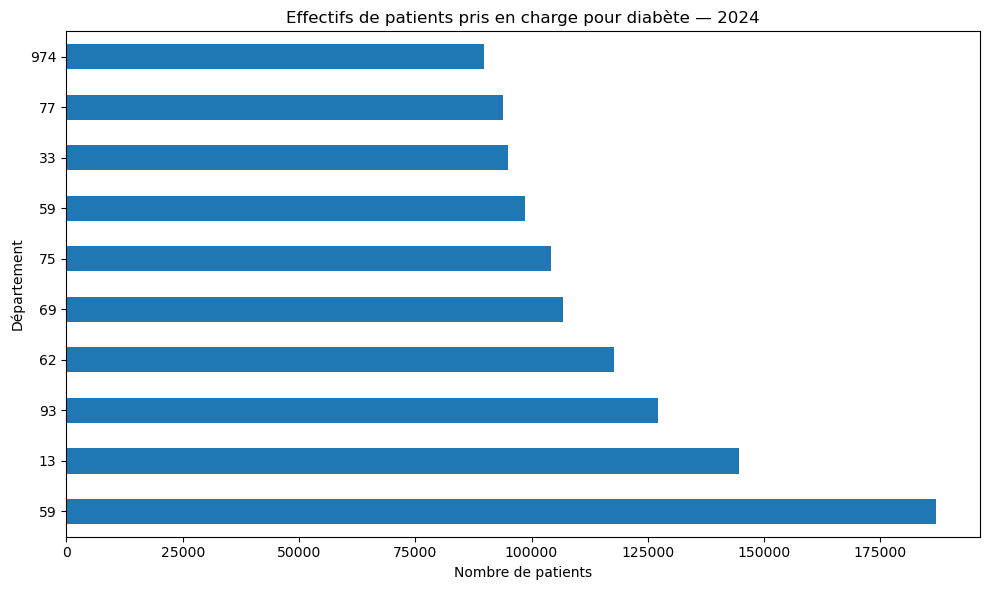

In [23]:
import matplotlib.pyplot as plt

top10.plot(
    x="dept",
    y="effectif_num",
    kind="barh",
    figsize=(10, 6),
    legend=False
)

plt.title("Effectifs de patients pris en charge pour diabète — 2024")
plt.xlabel("Nombre de patients")
plt.ylabel("Département")
plt.tight_layout()
plt.show()

In [24]:
df_travail.shape

(6363, 17)

## 7. Sauvegarder et documenter

In [25]:
dossier_interim = Path(
    r"D:\HealthPulse_AI_360\data\interim\diabete"
)

dossier_interim.mkdir(
    parents=True,
    exist_ok=True
)

sortie = dossier_interim / "diabete_2024_departements.csv"

df_travail.to_csv(
    sortie,
    index=False,
    encoding="utf-8-sig"
)

In [26]:
#Vérifier l'export

df_verification = pd.read_csv(
    sortie,
    dtype="string"
)

print(df_verification.shape)
print(df_travail.shape)

(6363, 17)
(6363, 17)


In [27]:
sortie

WindowsPath('D:/HealthPulse_AI_360/data/interim/diabete/diabete_2024_departements.csv')